# Hillslopes and channels: removing the resolution dependence with `channelQ`

goSPL couples fluvial incision and hillslope diffusion by operator splitting. By default the diffusion acts on **every** land cell, including the channel cells. A river is a line of single cells, so the diffusive flux its neighbours deliver into it grows as the cells shrink: the finer the mesh, the more the hillslopes fill the valleys, and the steeper the channels must become to carry that material away (Hergarten and Pietrek, 2023). The balance between the two processes then depends on the mesh resolution.

The optional `diffusion: channelQ` key (m³/yr) removes this dependence. Cells whose discharge reaches `channelQ` are **channels**:

* they are held at their elevation during the diffusion solve, so the hillslopes grade to them;
* the volume the hillslopes deliver to them joins the river load of the same step (with deposition on, the hillslope step runs between the incision and the sediment routing);
* a channel cell that would lose material to a lower neighbour keeps the loss, so the volume budget is exact.

This example runs the test of the goSPL GMD paper (Sect. 3.4): a 20 × 20 km block uplifted at $U = 1$ mm/yr, with fixed (base-level) edges, $K = 4\times10^{-5}$ m$^{1-2m}$/yr, $m = 0.5$, $n = 1$ and a land diffusivity $D = 0.2$ m²/yr, at 200, 100 and 50 m spacing, **with and without** `channelQ: 1.e6`. At steady state the channel steepness $k_s = S A^{1/2}$ should equal $U/K = 25$ m whatever the resolution.

**Choosing `channelQ`.** It is a discharge (the `FA` output), i.e. a channel-head drainage area times the rainfall: `channelQ = A_c × P`. Here 1 km² with 1 m/yr of rain gives `channelQ: 1.e6`. Keep $A_c$ at least about ten cell areas on the coarsest mesh you use, and check the mask on a first output (the cells with `FA ≥ channelQ` should outline the valley network you expect). See the goSPL user guide, *Hillslope processes*.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

from gospl.analyse.gridexport import grid_export
from scripts.channels import (channel_steepness, mean_elevation, n_steps,
                              load_mesh, read_step)

SPACINGS = (200, 100, 50)
QC = 1.0e6   # channelQ of the *_chan runs (m3/yr)

## Running the simulations

```bash
conda activate gospl
python make_mesh.py      # meshes (data/mesh200/100/50.npz) and the six input files
./run_all.sh             # or one run:  mpirun -np 4 gospl -i input-100_chan.yml
```

`input-<dx>.yml` lets the diffusion act on every cell; `input-<dx>_chan.yml` differs only by

```yaml
diffusion:
    hillslopeKa: 0.2
    hillslopeKm: 0.
    channelQ: 1.e6   # river cells (discharge >= channelQ, m3/yr) are held out of the diffusion
```

The six runs take about 15 minutes on 16 cores, most of it the two 50 m runs (3 Myr, `dt` = 5 kyr; the block reaches steady state after about 0.5 Myr and the runs continue to check that it holds).

## Channel steepness at steady state

$k_s$ is the median of $S A^{1/2}$ over the cells draining more than 1 km², with $S$ the steepest downhill slope along the mesh edges (with 1 m/yr of rain the discharge in m³/yr equals the drainage area in m²).

 spacing  ks, diffusion everywhere  ks, channelQ          mean z (m)
   200 m                      30.5          25.1        77 /    70
   100 m                      40.3          25.2       120 /    87
    50 m                      65.1          25.4       203 /   116
theory U/K = 25 m


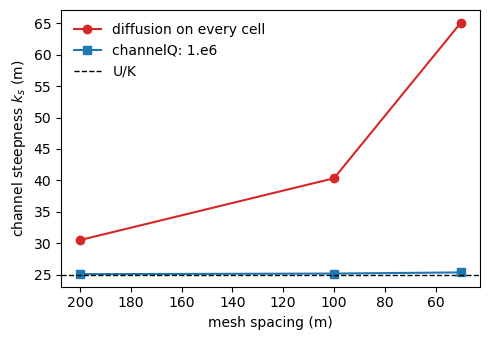

In [2]:
ks = {tag: [channel_steepness(f"sim_{dx}{tag}", dx) for dx in SPACINGS] for tag in ("", "_chan")}
zm = {tag: [mean_elevation(f"sim_{dx}{tag}", dx)[-1] for dx in SPACINGS] for tag in ("", "_chan")}

print(f"{'spacing':>8s} {'ks, diffusion everywhere':>25s} {'ks, channelQ':>13s}   {'mean z (m)':>17s}")
for i, dx in enumerate(SPACINGS):
    print(f"{dx:6d} m {ks[''][i]:25.1f} {ks['_chan'][i]:13.1f}   {zm[''][i]:7.0f} / {zm['_chan'][i]:5.0f}")
print("theory U/K = 25 m")

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(SPACINGS, ks[""], "o-", c="tab:red", label="diffusion on every cell")
ax.plot(SPACINGS, ks["_chan"], "s-", c="tab:blue", label="channelQ: 1.e6")
ax.axhline(25.0, c="k", ls="--", lw=1, label="U/K")
ax.set_xlabel("mesh spacing (m)")
ax.set_ylabel("channel steepness $k_s$ (m)")
ax.invert_xaxis()
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

Without `channelQ` the channels steepen as the mesh is refined, because the hillslopes deliver more material into the one-cell-wide rivers. With `channelQ` the steepness stays at $U/K$ at every resolution: the diffusion now shapes only the hillslopes, and the channel slopes follow the fluvial law.

## Approach to steady state

The mean elevation of the block through time. Without `channelQ`, refining the mesh raises the whole landscape; with it, the mean elevation still grows a little with resolution, as finer meshes resolve smaller and steeper headwaters (the paper reports 70 to 96 m without any diffusion).

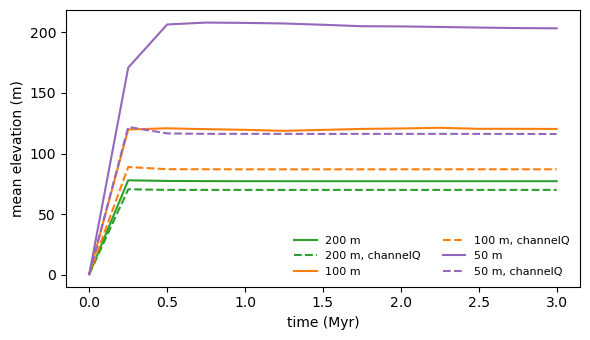

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.5))
colors = {200: "tab:green", 100: "tab:orange", 50: "tab:purple"}
for dx in SPACINGS:
    for tag, ls in (("", "-"), ("_chan", "--")):
        z = mean_elevation(f"sim_{dx}{tag}", dx)
        t = np.arange(len(z)) * 0.25
        ax.plot(t, z, ls, c=colors[dx], label=f"{dx} m{', channelQ' if tag else ''}")
ax.set_xlabel("time (Myr)")
ax.set_ylabel("mean elevation (m)")
ax.legend(frameon=False, ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

## Landscapes at 50 m

Final elevation of the 50 m runs, with the channel cells (`FA ≥ channelQ`) in black. Without `channelQ` the valleys are broad and the relief is high; with it the hillslopes grade to narrow channels.

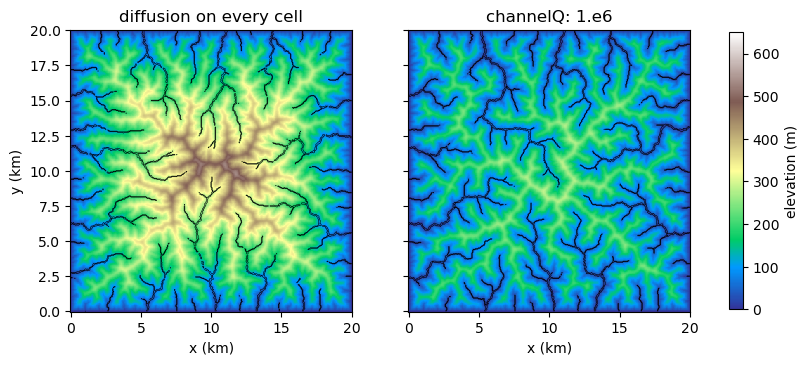

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
dx = 50
for ax, tag, title in zip(axs, ("", "_chan"), ("diffusion on every cell", "channelQ: 1.e6")):
    run = f"sim_{dx}{tag}"
    g = grid_export(f"{run}/h5", f"data/mesh{dx}.npz", n_steps(run) - 1, spacing=dx)
    x, y = np.asarray(g["x"]) / 1e3, np.asarray(g["y"]) / 1e3
    im = ax.pcolormesh(x, y, g["elev"], cmap="terrain", vmin=0, vmax=650, shading="auto")
    ax.contour(x, y, np.asarray(g["FA"]) >= QC, levels=[0.5], colors="k", linewidths=0.4)
    ax.set_title(title)
    ax.set_xlabel("x (km)")
    ax.set_aspect("equal")
axs[0].set_ylabel("y (km)")
fig.colorbar(im, ax=axs, label="elevation (m)", shrink=0.8)
plt.show()

## Take-away

* With diffusion on every cell, a hillslope diffusivity is tied to the mesh resolution: the same `hillslopeKa` gives different channels, relief and erosion rates at different spacings.
* `channelQ` makes the channels independent of the resolution, so a diffusivity measured at the hillslope scale can be used on any mesh fine enough to resolve hillslopes.
* It works with the linear and non-linear hillslope laws, the soil model, stratigraphy, dual lithology and provenance tracers (the supply carries the composition of the eroded hillslope material). It is off by default.

**Reference.** Hergarten, S. and Pietrek, A.: Self-organization of channels and hillslopes in models of fluvial landform evolution and its potential for solving scaling issues, Earth Surf. Dynam., 11, 741–755, 2023.